# Mouhamed Cisse

# Problem 1

## 1

AlexNet is a Convolutional Neural Network used for image classification. It processes an image through several layers to extract features and then classify the object in the image.

**The convolutional layers** perform feature extraction. They apply filters to the image to detect patterns such as edges, textures, and shapes. 

**Max pooling layers** reduce the size of the feature maps by keeping the most important values. This reduces computation and helps the model handle small changes in the image.

**The flatten layer** converts the feature maps into a one dimensional vector. This vector is then passed to fully connected layers, which act as a classifier and produce the final prediction.


## 2 

### Overfitting

The model performs well on the training set but poorly on the test set.
The model learns patterns from the training data and also learns noise.
This reduces the ability to generalize to new data.

### Techniques to overcome them: 

Dropout is a technique where some neurons are randomly deactivated during training. This prevents the network from relying too much on specific neurons. Regularization methods such as L1 and L2 regularization also help by penalizing large weights in the model.

Early stopping also reduces overfitting. Training stops when the validation error starts increasing, which prevents the model from learning noise in the training data.

### Underfitting

The model performs poorly on the training set and also poorly on the test set.
The model fails to learn the underlying structure of the data.
The model is too simple or not trained enough.

To reduce underfitting, the model capacity can be increased by adding more layers or more filters in the CNN. Training the model for more epochs or improving feature extraction can also help the network learn more complex patterns in the data.

## 3 Dataset Visualisation

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from keras.models import Sequential
import pandas as pd
import seaborn as sns
import pickle
import random

In [2]:
with open("Problem 1/train.p", "rb") as f:
	train = pickle.load(f)
with open("Problem 1/test.p", "rb") as f:
	test = pickle.load(f)	
with open("Problem 1/valid.p", "rb") as f:
	valid = pickle.load(f)

In [3]:
X_train, y_train = train['features'], train['labels']
X_validation, y_validation = valid['features'], valid['labels']
X_test, y_test = test['features'], test['labels']

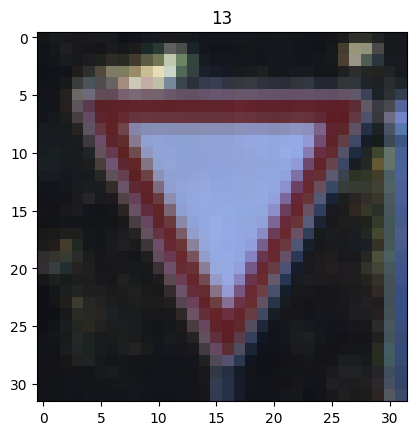

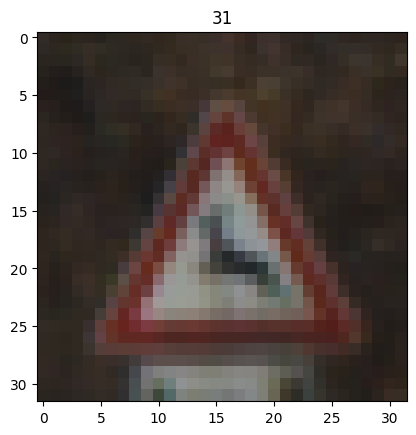

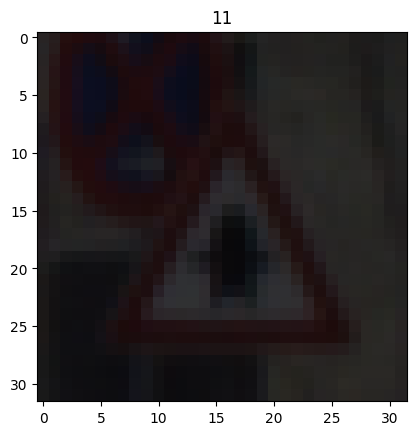

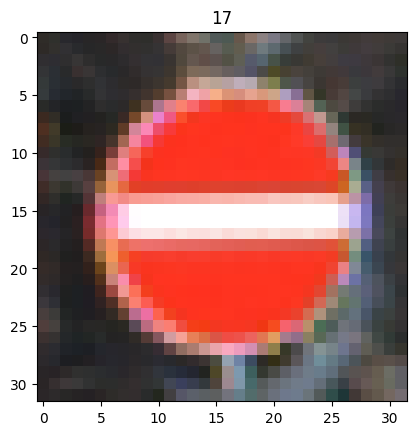

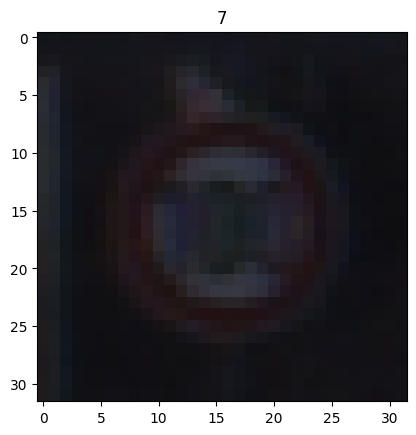

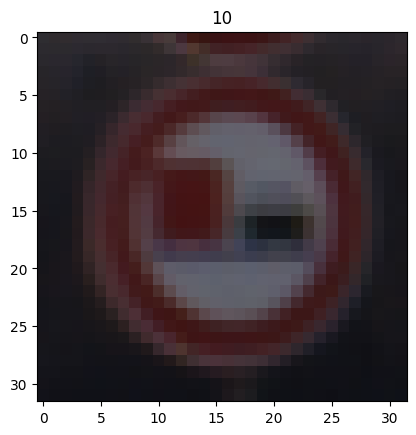

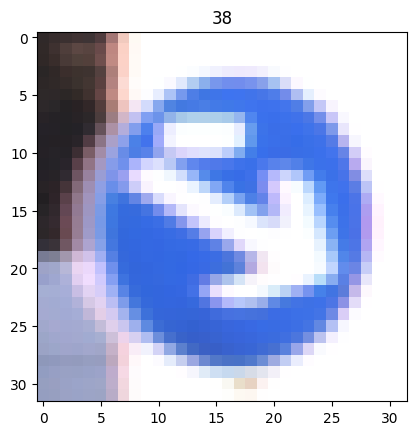

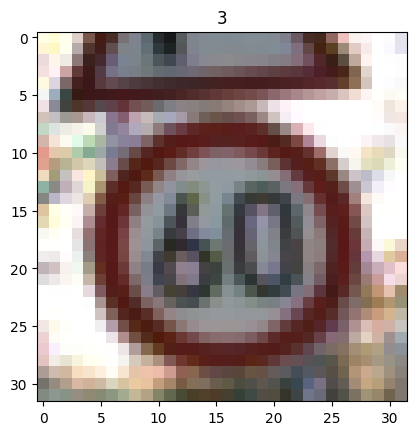

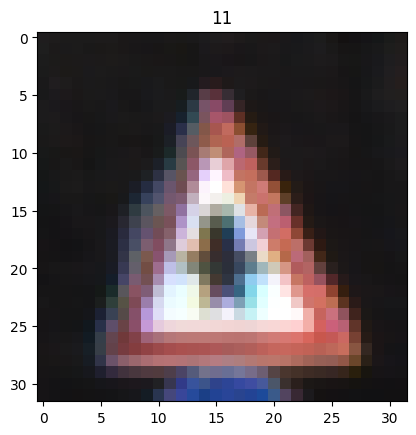

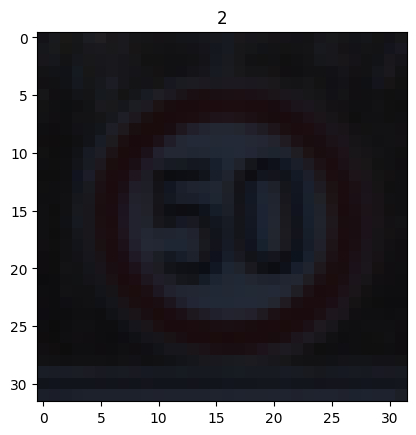

In [ ]:
# Visualize some of the training data
for _ in range(10):
    i = np.random.randint(0, len(X_train))
    plt.imshow(X_train[i])
    plt.title(y_train[i])
    plt.show()

In [ ]:
# Number of examples for each class in the training set
for i in range(len(np.unique(y_train))):
	print(f"Number of examples for class {i}: {np.sum(y_train == i)}")

Number of examples for class 0: 180
Number of examples for class 1: 1980
Number of examples for class 2: 2010
Number of examples for class 3: 1260
Number of examples for class 4: 1770
Number of examples for class 5: 1650
Number of examples for class 6: 360
Number of examples for class 7: 1290
Number of examples for class 8: 1260
Number of examples for class 9: 1320
Number of examples for class 10: 1800
Number of examples for class 11: 1170
Number of examples for class 12: 1890
Number of examples for class 13: 1920
Number of examples for class 14: 690
Number of examples for class 15: 540
Number of examples for class 16: 360
Number of examples for class 17: 990
Number of examples for class 18: 1080
Number of examples for class 19: 180
Number of examples for class 20: 300
Number of examples for class 21: 270
Number of examples for class 22: 330
Number of examples for class 23: 450
Number of examples for class 24: 240
Number of examples for class 25: 1350
Number of examples for class 26: 5

## 4 Training

In [6]:
# Preprocessing: Grayscaling and Normalization
from sklearn.utils import shuffle
X_train, y_train = shuffle(X_train, y_train)

X_train_gray = np.sum(X_train/3, axis = 3, keepdims = True)
X_train_norm = X_train_gray/255
X_test_gray = np.sum(X_test/3, axis = 3, keepdims = True)
X_test_norm = X_test_gray/255
X_validation_gray = np.sum(X_validation/3, axis = 3, keepdims = True)
X_validation_norm = X_validation_gray/255

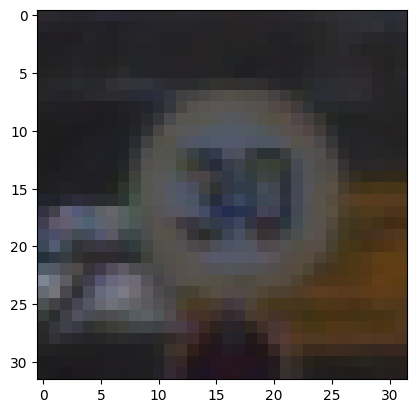

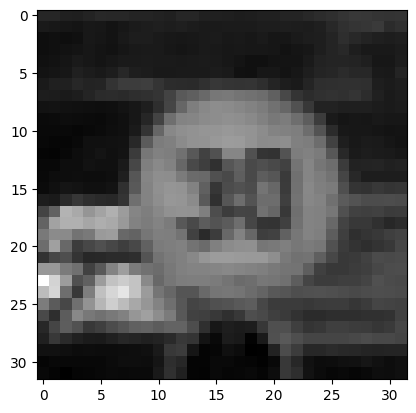

In [7]:
# Visualize the effect of grayscaling and normalization
i = random.randint(1, len(X_train_gray))
plt.imshow(X_train[i], cmap = 'gray')
plt.show()
plt.imshow(X_train_norm[i], cmap = 'gray')
plt.show()

In [8]:
# Build the model
model = Sequential()
model.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(32,32,1)))
model.add(layers.MaxPooling2D(pool_size=(2,2)))

model.add(layers.Conv2D(64, (3,3), activation='relu'))
model.add(layers.AveragePooling2D(pool_size=(2,2)))

model.add(layers.Flatten())
model.add(layers.Dense(128, activation = 'relu'))
model.add(layers.Dense(43, activation = 'softmax'))
model.summary()

/opt/anaconda3/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 6, 6, 64)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 43)             │         5,547 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 319,403 (1.22 MB)

 Trainable params: 319,403 (1.22 MB)

 Non-trainable params: 0 (0.00 B)

In [9]:
# parameterizing
model.compile("Adam",  loss = 'sparse_categorical_crossentropy', metrics = ['accuracy'])

In [10]:
# training loop
history = model.fit(X_train_norm,
                 y_train, 
                 batch_size = 500,
                 epochs = 15,
                 verbose = 1,
                 validation_data = (X_validation_norm, y_validation))

Epoch 1/15
70/70 ━━━━━━━━━━━━━━━━━━━━ 5s 61ms/step - accuracy: 0.1836 - loss: 3.1832 - val_accuracy: 0.3565 - val_loss: 2.5931
Epoch 2/15
70/70 ━━━━━━━━━━━━━━━━━━━━ 4s 59ms/step - accuracy: 0.5713 - loss: 1.6116 - val_accuracy: 0.6465 - val_loss: 1.3093
Epoch 3/15
70/70 ━━━━━━━━━━━━━━━━━━━━ 4s 61ms/step - accuracy: 0.7756 - loss: 0.8474 - val_accuracy: 0.7546 - val_loss: 0.9627
Epoch 4/15
70/70 ━━━━━━━━━━━━━━━━━━━━ 4s 61ms/step - accuracy: 0.8519 - loss: 0.5793 - val_accuracy: 0.7961 - val_loss: 0.7950
Epoch 5/15
70/70 ━━━━━━━━━━━━━━━━━━━━ 4s 63ms/step - accuracy: 0.8936 - loss: 0.4368 - val_accuracy: 0.8181 - val_loss: 0.7032
Epoch 6/15
70/70 ━━━━━━━━━━━━━━━━━━━━ 4s 61ms/step - accuracy: 0.9161 - loss: 0.3503 - val_accuracy: 0.8302 - val_loss: 0.6707
Epoch 7/15
70/70 ━━━━━━━━━━━━━━━━━━━━ 4s 63ms/step - accuracy: 0.9341 - loss: 0.2857 - val_accuracy: 0.8449 - val_loss: 0.6315
Epoch 8/15
70/70 ━━━━━━━━━━━━━━━━━━━━ 4s 60ms/step - accuracy: 0.9424 - loss: 0.2484 - val_accuracy: 0.8574 - v

In [11]:
# Test Accuracy
score = model.evaluate(X_test_norm, y_test)
print('Test Accuracy: {}'.format(score[1]))

395/395 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8647 - loss: 0.8581
Test Accuracy: 0.8646872639656067


## 5 Improving the model

In [12]:
# 1- More epochs
history = model.fit(X_train_norm,
				 y_train,
				 batch_size = 500,
				 epochs = 30,
				 verbose = 1,
				 validation_data = (X_validation_norm, y_validation))
# Test Accuracy
score = model.evaluate(X_test_norm, y_test)
print('Test Accuracy: {}'.format(score[1]))

Epoch 1/30
70/70 ━━━━━━━━━━━━━━━━━━━━ 5s 68ms/step - accuracy: 0.9791 - loss: 0.0959 - val_accuracy: 0.8800 - val_loss: 0.5957
Epoch 2/30
70/70 ━━━━━━━━━━━━━━━━━━━━ 4s 61ms/step - accuracy: 0.9809 - loss: 0.0880 - val_accuracy: 0.8853 - val_loss: 0.5658
Epoch 3/30
70/70 ━━━━━━━━━━━━━━━━━━━━ 5s 67ms/step - accuracy: 0.9828 - loss: 0.0782 - val_accuracy: 0.8823 - val_loss: 0.6476
Epoch 4/30
70/70 ━━━━━━━━━━━━━━━━━━━━ 4s 63ms/step - accuracy: 0.9851 - loss: 0.0714 - val_accuracy: 0.8810 - val_loss: 0.6351
Epoch 5/30
70/70 ━━━━━━━━━━━━━━━━━━━━ 4s 62ms/step - accuracy: 0.9858 - loss: 0.0646 - val_accuracy: 0.8887 - val_loss: 0.6014
Epoch 6/30
70/70 ━━━━━━━━━━━━━━━━━━━━ 4s 60ms/step - accuracy: 0.9869 - loss: 0.0610 - val_accuracy: 0.8764 - val_loss: 0.6514
Epoch 7/30
70/70 ━━━━━━━━━━━━━━━━━━━━ 4s 61ms/step - accuracy: 0.9880 - loss: 0.0567 - val_accuracy: 0.8832 - val_loss: 0.6516
Epoch 8/30
70/70 ━━━━━━━━━━━━━━━━━━━━ 4s 61ms/step - accuracy: 0.9890 - loss: 0.0506 - val_accuracy: 0.8884 - v

In [ ]:
# 2- Additional convolutional layer

model = Sequential()
model.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(32,32,1)))
model.add(layers.MaxPooling2D(pool_size=(2,2)))

model.add(layers.Conv2D(64, (3,3), activation='relu'))
model.add(layers.AveragePooling2D(pool_size=(2,2)))

model.add(layers.Conv2D(128, (3,3), activation='relu'))
model.add(layers.AveragePooling2D(pool_size=(2,2)))

model.add(layers.Flatten())
model.add(layers.Dense(128, activation = 'relu'))
model.add(layers.Dense(43, activation = 'softmax'))
model.summary()

# parameterizing
model.compile("Adam",  loss = 'sparse_categorical_crossentropy', metrics = ['accuracy'])

history = model.fit(X_train_norm,
				 y_train,
				 batch_size = 500,
				 epochs = 30,
				 verbose = 1,
				 validation_data = (X_validation_norm, y_validation))
# Test Accuracy
score = model.evaluate(X_test_norm, y_test)
print('Test Accuracy: {}'.format(score[1]))

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 30, 30, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 6, 6, 64)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 4, 4, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_2             │ (None, 2, 2, 128)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 43)             │         5,547 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 163,883 (640.17 KB)

 Trainable params: 163,883 (640.17 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
70/70 ━━━━━━━━━━━━━━━━━━━━ 6s 73ms/step - accuracy: 0.0915 - loss: 3.4519 - val_accuracy: 0.1501 - val_loss: 3.3767
Epoch 2/30
70/70 ━━━━━━━━━━━━━━━━━━━━ 5s 71ms/step - accuracy: 0.2891 - loss: 2.7049 - val_accuracy: 0.3853 - val_loss: 2.3608
Epoch 3/30
70/70 ━━━━━━━━━━━━━━━━━━━━ 5s 70ms/step - accuracy: 0.5245 - loss: 1.6922 - val_accuracy: 0.5544 - val_loss: 1.6539
Epoch 4/30
70/70 ━━━━━━━━━━━━━━━━━━━━ 5s 68ms/step - accuracy: 0.6596 - loss: 1.1781 - val_accuracy: 0.6243 - val_loss: 1.3625
Epoch 5/30
70/70 ━━━━━━━━━━━━━━━━━━━━ 5s 68ms/step - accuracy: 0.7357 - loss: 0.9098 - val_accuracy: 0.6823 - val_loss: 1.1943
Epoch 6/30
70/70 ━━━━━━━━━━━━━━━━━━━━ 5s 70ms/step - accuracy: 0.7782 - loss: 0.7560 - val_accuracy: 0.6993 - val_loss: 1.1288
Epoch 7/30
70/70 ━━━━━━━━━━━━━━━━━━━━ 5s 71ms/step - accuracy: 0.8140 - loss: 0.6428 - val_accuracy: 0.7215 - val_loss: 1.0376
Epoch 8/30
70/70 ━━━━━━━━━━━━━━━━━━━━ 5s 70ms/step - accuracy: 0.8409 - loss: 0.5543 - val_accuracy: 0.7494 - v

In [ ]:
# 3- Additional epochs and convolutional layer + Dropout 

model = Sequential()
model.add(layers.Conv2D(32, (3, 3), activation='relu', input_shape=(32,32,1)))
model.add(layers.MaxPooling2D(pool_size=(2,2)))

model.add(layers.Conv2D(64, (3,3), activation='relu'))
model.add(layers.AveragePooling2D(pool_size=(2,2)))

model.add(layers.Conv2D(128, (3,3), activation='relu'))
model.add(layers.AveragePooling2D(pool_size=(2,2)))

model.add(layers.Flatten())
model.add(layers.Dense(128, activation = 'relu'))
model.add(layers.Dense(43, activation = 'softmax'))
model.summary()

# parameterizing
model.compile("Adam",  loss = 'sparse_categorical_crossentropy', metrics = ['accuracy'])

history = model.fit(X_train_norm,
				 y_train,
				 batch_size = 500,
				 epochs = 30,
				 verbose = 1,
				 validation_data = (X_validation_norm, y_validation))
# Test Accuracy
score = model.evaluate(X_test_norm, y_test)
print('Test Accuracy: {}'.format(score[1]))

## 6 Different architectures

In [ ]:
model = Sequential()

model.add(layers.Conv2D(32, (3,3),  activation='relu', input_shape=(32,32,1)))
model.add(layers.Conv2D(32, (3,3),  activation='relu'))
model.add(layers.MaxPooling2D((2,2)))

model.add(layers.Conv2D(64, (3,3),  activation='relu'))
model.add(layers.Conv2D(64, (3,3),  activation='relu'))
model.add(layers.MaxPooling2D((2,2)))

model.add(layers.Conv2D(128, (3,3),  activation='relu'))
model.add(layers.MaxPooling2D((2,2)))

model.add(layers.Flatten())
model.add(layers.Dense(256, activation='relu'))
model.add(layers.Dropout(0.5))
model.add(layers.Dense(43, activation='softmax'))

model.summary()

# parameterizing
model.compile("Adam",  loss = 'sparse_categorical_crossentropy', metrics = ['accuracy'])

history = model.fit(X_train_norm,
				 y_train,
				 batch_size = 500,
				 epochs = 15,
				 verbose = 1,
				 validation_data = (X_validation_norm, y_validation))
# Test Accuracy
score = model.evaluate(X_test_norm, y_test)
print('Test Accuracy: {}'.format(score[1]))

In [15]:
model2 = Sequential()

model2.add(layers.Conv2D(32, (3,3), activation='relu', input_shape=(32,32,1)))
model2.add(layers.MaxPooling2D((2,2)))

model2.add(layers.Conv2D(64, (3,3), activation='relu'))
model2.add(layers.MaxPooling2D((2,2)))

model2.add(layers.Flatten())
model2.add(layers.Dense(128, activation='relu'))
model2.add(layers.Dense(43, activation='softmax'))

model2.compile("Adam", loss='sparse_categorical_crossentropy', metrics=['accuracy'])

history2 = model2.fit(
    X_train_norm,
    y_train,
    batch_size=500,
    epochs=15,
    validation_data=(X_validation_norm, y_validation)
)

Epoch 1/15
70/70 ━━━━━━━━━━━━━━━━━━━━ 5s 69ms/step - accuracy: 0.2392 - loss: 3.0361 - val_accuracy: 0.4181 - val_loss: 2.3236
Epoch 2/15
70/70 ━━━━━━━━━━━━━━━━━━━━ 5s 66ms/step - accuracy: 0.6447 - loss: 1.3491 - val_accuracy: 0.6805 - val_loss: 1.2153
Epoch 3/15
70/70 ━━━━━━━━━━━━━━━━━━━━ 5s 67ms/step - accuracy: 0.8417 - loss: 0.6404 - val_accuracy: 0.8059 - val_loss: 0.8024
Epoch 4/15
70/70 ━━━━━━━━━━━━━━━━━━━━ 4s 62ms/step - accuracy: 0.9058 - loss: 0.4015 - val_accuracy: 0.8302 - val_loss: 0.7179
Epoch 5/15
70/70 ━━━━━━━━━━━━━━━━━━━━ 4s 62ms/step - accuracy: 0.9353 - loss: 0.2810 - val_accuracy: 0.8478 - val_loss: 0.6346
Epoch 6/15
70/70 ━━━━━━━━━━━━━━━━━━━━ 4s 63ms/step - accuracy: 0.9532 - loss: 0.2121 - val_accuracy: 0.8605 - val_loss: 0.5682
Epoch 7/15
70/70 ━━━━━━━━━━━━━━━━━━━━ 4s 64ms/step - accuracy: 0.9630 - loss: 0.1714 - val_accuracy: 0.8671 - val_loss: 0.6069
Epoch 8/15
70/70 ━━━━━━━━━━━━━━━━━━━━ 5s 69ms/step - accuracy: 0.9706 - loss: 0.1407 - val_accuracy: 0.8753 - v

In [18]:
# Test Accuracy
score = model2.evaluate(X_test_norm, y_test)
print('Test Accuracy: {}'.format(score[1]))

395/395 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8952 - loss: 0.7547
Test Accuracy: 0.8952494263648987


In [16]:
model3 = Sequential()

model3.add(layers.Conv2D(32, (3,3), activation='relu', input_shape=(32,32,1)))
model3.add(layers.MaxPooling2D((2,2)))
model3.add(layers.Dropout(0.25))

model3.add(layers.Conv2D(64, (3,3), activation='relu'))
model3.add(layers.MaxPooling2D((2,2)))
model3.add(layers.Dropout(0.25))

model3.add(layers.Flatten())
model3.add(layers.Dense(128, activation='relu'))
model3.add(layers.Dropout(0.5))
model3.add(layers.Dense(43, activation='softmax'))

model3.compile("Adam", loss='sparse_categorical_crossentropy', metrics=['accuracy'])

history3 = model3.fit(
    X_train_norm,
    y_train,
    batch_size=500,
    epochs=15,
    validation_data=(X_validation_norm, y_validation)
)

Epoch 1/15
70/70 ━━━━━━━━━━━━━━━━━━━━ 6s 73ms/step - accuracy: 0.1053 - loss: 3.4177 - val_accuracy: 0.2782 - val_loss: 3.0540
Epoch 2/15
70/70 ━━━━━━━━━━━━━━━━━━━━ 5s 75ms/step - accuracy: 0.3505 - loss: 2.4801 - val_accuracy: 0.5388 - val_loss: 1.8625
Epoch 3/15
70/70 ━━━━━━━━━━━━━━━━━━━━ 5s 67ms/step - accuracy: 0.5310 - loss: 1.6567 - val_accuracy: 0.7304 - val_loss: 1.1409
Epoch 4/15
70/70 ━━━━━━━━━━━━━━━━━━━━ 5s 72ms/step - accuracy: 0.6459 - loss: 1.2018 - val_accuracy: 0.7971 - val_loss: 0.8348
Epoch 5/15
70/70 ━━━━━━━━━━━━━━━━━━━━ 5s 72ms/step - accuracy: 0.7150 - loss: 0.9549 - val_accuracy: 0.8329 - val_loss: 0.6506
Epoch 6/15
70/70 ━━━━━━━━━━━━━━━━━━━━ 5s 72ms/step - accuracy: 0.7621 - loss: 0.7875 - val_accuracy: 0.8633 - val_loss: 0.5428
Epoch 7/15
70/70 ━━━━━━━━━━━━━━━━━━━━ 5s 70ms/step - accuracy: 0.7957 - loss: 0.6677 - val_accuracy: 0.8868 - val_loss: 0.4523
Epoch 8/15
70/70 ━━━━━━━━━━━━━━━━━━━━ 5s 68ms/step - accuracy: 0.8233 - loss: 0.5779 - val_accuracy: 0.9007 - v

In [17]:
# Test Accuracy
score = model3.evaluate(X_test_norm, y_test)
print('Test Accuracy: {}'.format(score[1]))

395/395 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9217 - loss: 0.3141
Test Accuracy: 0.9216943979263306


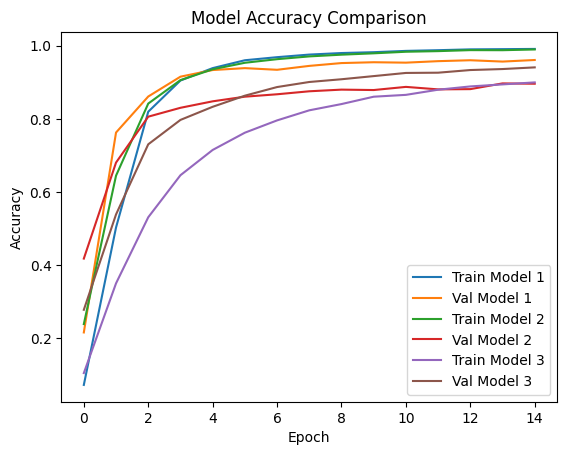

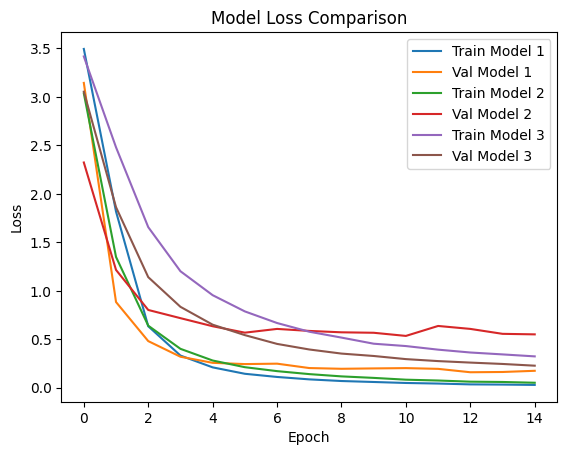

In [ ]:
import matplotlib.pyplot as plt

# Accuracy
plt.figure()
plt.plot(history.history['accuracy'], label='Train Model 1')
plt.plot(history.history['val_accuracy'], label='Val Model 1')

plt.plot(history2.history['accuracy'], label='Train Model 2')
plt.plot(history2.history['val_accuracy'], label='Val Model 2')

plt.plot(history3.history['accuracy'], label='Train Model 3')
plt.plot(history3.history['val_accuracy'], label='Val Model 3')

plt.title("Model Accuracy Comparison")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()


# Loss
plt.figure()
plt.plot(history.history['loss'], label='Train Model 1')
plt.plot(history.history['val_loss'], label='Val Model 1')

plt.plot(history2.history['loss'], label='Train Model 2')
plt.plot(history2.history['val_loss'], label='Val Model 2')

plt.plot(history3.history['loss'], label='Train Model 3')
plt.plot(history3.history['val_loss'], label='Val Model 3')

plt.title("Model Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()